In [1]:
%load_ext autoreload
%autoreload 2

import os
import jax
import numpy as np

import numpy as np
from flax import serialization

from c3po.analysis.analysis import C3poAnalysis
from c3po.model.model import C3PO

# analysis=C3poAnalysis(None, None, None)

# Load Data

In [ ]:
from utils import download_ebrains_file
from pathlib import Path
local_dir = os.environ.get("C3PO_CACHE_DIR", "/stelmo/sam/tmp")  # Use environment variable if set, otherwise default

data_path = download_ebrains_file(
    remote_path="sharing_v4/navigation/of/27765_2.mat",
    local_path=local_dir / "27765_2.mat",
)

In [4]:
import numpy as np
from scipy.io import loadmat


data = loadmat(data_path)


def mat_fields(s):
    """Return field names for a MATLAB struct (np.void or structured ndarray)."""
    if isinstance(s, np.ndarray) and s.dtype.names:
        return s.dtype.names
    if isinstance(s, np.void) and s.dtype.names:
        return s.dtype.names
    raise TypeError("Not a MATLAB struct (np.void/structured ndarray).")


# The 'Dsession' key gives the main struct
Dsession = data["Dsession"]

t = Dsession["t"][0, 0].flatten()  # times
x = Dsession["x"][0, 0].flatten()  # x positions
y = Dsession["y"][0, 0].flatten()  # y positions
speed = Dsession["speed"][0, 0].flatten()  #
thetaphase = Dsession["theta"][0, 0].flatten()  #
units = Dsession["units"][0, 0].flatten()  # unit data (more parsing below)
unit_cluster_id = units["mec"][0]["acorrCluId"][:]

head_dir = Dsession["hd"][0, 0].flatten()
hd_cont = np.unwrap(head_dir)
ang_vel = np.gradient(hd_cont, np.median(np.diff(t)))
ind_jump = np.where(np.diff(t) > 0.1)[0]
ang_vel[ind_jump] = 0
ang_vel[ind_jump + 1] = 0

In [5]:
t_spikes = np.arange(t[0], t[-1], 0.005)
spikes = []
for uu in range(len(units["mec"][0]["spikeTimes"])):
    spikes.append(units["mec"][0]["spikeTimes"][uu][0].flatten())

len(spikes)


from scipy.ndimage import gaussian_filter1d
from tqdm import tqdm

smoothing_window = 0.02  # in seconds
# smoothing_window = 0.003  # in seconds
dt = t_spikes[1] - t_spikes[0]
smoothing_window_bins = int(smoothing_window / dt)
rates = []

for uu in tqdm(range(len(spikes))):
    rate, _ = np.histogram(
        spikes[uu], bins=np.concatenate([t_spikes, [t_spikes[-1] + (dt)]])
    )
    # rate = np.convolve(
    #     rate,
    #     np.ones(smoothing_window_bins) / smoothing_window_bins,
    #     mode="same",
    # )
    rate = gaussian_filter1d(
        rate[:, None].astype("float"),
        sigma=smoothing_window_bins,
        axis=0,
        mode="nearest",
    )

    rates.append(rate / (t[1] - t[0]))  # in Hz
rates = np.squeeze(rates).T
mua = rates.sum(axis=1)

  0%|          | 0/460 [00:00<?, ?it/s]

100%|██████████| 460/460 [00:10<00:00, 45.46it/s]


In [6]:
# plt.hist(np.log10(np.diff(t)))
# plt.yscale("log")
# np.median(np.diff(t))
dt = np.diff(t)

ind_valid = (dt < 0.02).astype(int)  # only use intervals with dt < 20 ms
starts = np.where(np.diff(ind_valid) == 1)[0] + 1
ends = np.where(np.diff(ind_valid) == -1)[0] + 1
if ind_valid[0]:
    starts = np.insert(starts, 0, 0)
if ind_valid[-1]:
    ends = np.append(ends, len(ind_valid))
valid_intervals = [[t[s], t[e]] for s, e in zip(starts, ends)]

In [7]:
def angular_distance(ang, ref_ang):
    """
    Compute signed angular distance between two angles (in radians).
    Returns a value in [-π, π].
    """
    delta = np.arctan2(np.sin(ang - ref_ang), np.cos(ang - ref_ang))
    return delta


# t            = Dsession["t"][0, 0].flatten()  # times   (100 Hz sampling)
hd_lmt = Dsession["lmt"][0][0][0][0][0]["hd"][0][0]["XA"][0][0].flatten()
id_lmt = Dsession["lmt"][0][0][0][0][0]["id"][0][0]["XA"][0][0].flatten()
pos_lmt = Dsession["lmt"][0][0][0][0][0]["pos"][0][0]["XA"][0][0]

# calculate decode errors #
moser_hd_error = angular_distance(id_lmt, head_dir)
moser_pos_error = np.sqrt((pos_lmt[:, 0] - x) ** 2 + (pos_lmt[:, 1] - y) ** 2)

# Load c3po

In [8]:
from c3po.tables.dev_tables import C3POStorage
import matplotlib.pyplot as plt

C3POStorage()  # .alter()
model_name = "mec_wavenet_25843_all_cells"
model_name = "mec_wavenet_all_cells"


# model_name = "moser_mec_29502_1_openfield_wavenet_all_cells"
# model_name = f"mec_{data_name.split('/')[-1].split('.')[0]}_jan2026"

# key = {"model_name": "mec_wavenet_all_cells"}
key = dict(model_name=model_name)

analysis = (C3POStorage & key).fetch_analysis_object()

analysis.load_embedding(f"/stelmo/sam/c3po_results/{key['model_name']}_embedding.npz")

diff_t = np.diff(analysis.t)
bad_diff = np.where(diff_t > 0.1)[0] + 1
bad_diff = np.concatenate([[0], bad_diff, np.array([len(analysis.t)])])
no_gap_intervals = []
for i in range(len(bad_diff) - 1):
    no_gap_intervals.append((analysis.t[bad_diff[i]], analysis.t[bad_diff[i + 1] - 1]))
no_gap_intervals = np.array(no_gap_intervals)[:-7]

t_interp = np.arange(analysis.t[0], analysis.t[-1], 0.001)
analysis.interpolate_context(t_interp)
analysis.fit_context_pca(fit_intervals=no_gap_intervals[5:], interpolated=False)

# Just showing how to access the variables
# t = analysis.t
z = analysis.z
c = analysis.c
c_pca = analysis.c_pca
t_interp = analysis.t_interp
c_interp = analysis.c_interp
c_pca_interp = analysis.c_pca_interp

entry = (C3POStorage & key).fetch1()
latent_dim = entry["latent_dim"]
context_dim = entry["context_dim"]

# define figure directory
from c3po.analysis.analysis import figure_directory
from pathlib import Path

figure_directory = Path(figure_directory)
figure_folder = figure_directory / "Fig3" / "mec_open_field" / model_name
os.makedirs(figure_folder, exist_ok=True)
plt.rcParams["svg.fonttype"] = "none"  # to get editable text in Illustrator

/home/sambray/.local/lib/python3.10/site-packages/datajoint/plugin.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources  # requires setuptools<82
[2026-10-29 12:19:41,929][INFO]: DataJoint 0.14.9 connected to sambray@lmf-db.cin.ucsf.edu:3306


In [9]:
from c3po.analysis.intervals import interval_list_contains_ind
ind_rates =interval_list_contains_ind(no_gap_intervals,  t_spikes)
rates = rates[ind_rates]
t_spikes = t_spikes[ind_rates]
mua = mua[ind_rates]

# Calculate the c3po firing rate

In [10]:
c = analysis.c
z_neuron =analysis.params['params']['embedding']['encoder']['encoder_matrix']

In [14]:
t_ = analysis.t
delta_t = np.concatenate([np.array([1]), np.diff(t_)])
delta_t = gaussian_filter1d(
    delta_t[:, None],
    sigma=10,
    axis=0,
    mode="nearest",
)[:,0]
# mua = 1/delta_t

big_lam = 1/delta_t

cum_spikes = rates.mean(axis=0)
gamma = cum_spikes / np.sum(cum_spikes)

cz = np.dot(c, z_neuron.T)
zz = np.sum(z_neuron**2, axis=1)

cz.shape, zz.shape

from scipy.special import logsumexp
exponent = cz+zz[None,:]+np.log(gamma[None,:])
log_alpha = logsumexp(exponent, axis=1)

log_lam = np.log(big_lam[:, None]) + np.log(gamma[None,:]) - log_alpha[:, None] + cz + zz[None,:]

In [12]:
delta_t.shape

(1273703,)

In [13]:
cum_spikes = rates.mean(axis=0)
gamma = cum_spikes / np.sum(cum_spikes)

In [183]:
cz = np.dot(c, z_neuron.T)
zz = np.sum(z_neuron**2, axis=1)

cz.shape, zz.shape

((1273703, 460), (460,))

In [184]:
log_lam = -np.log(delta_t[:, None]) + np.log(gamma[None,:])# + cz + zz[None,:]

In [185]:
log_lam.shape

(1273703, 460)

ValueError: Format specifier missing precision

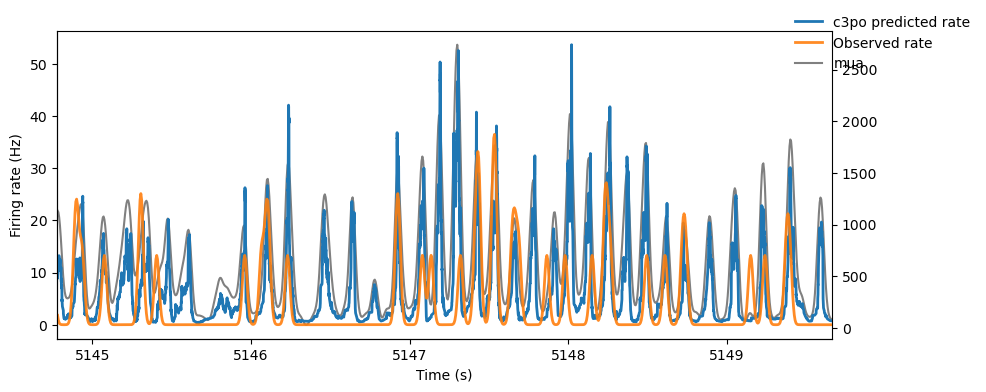

In [ ]:
i = 60
i = 333

st = 301500 -200
ind = slice(st, st + 6000)
# st = 3000 #+50#0*200
# ind = slice(st, st + 5000)

t_st = analysis.t[ind][0]
t_end = analysis.t[ind][-1]

ind_rate = np.where(np.logical_and(t_spikes>t_st, t_spikes<t_end))[0]

fig, ax = plt.subplots(figsize=(10, 4))


ax2 = ax.twinx()
ax.set_zorder(2)
ax.patch.set_visible(False)
ax2.plot(t_spikes[ind_rate], mua[ind_rate,], label=f"mua", color="grey",zorder=-1)
# ax2.plot(analysis.t[ind], 1/delta_t[ind], label=f"1/delta_t", color="red",zorder=-1)

c1 = "C0"
c2 = "C1"
c3 = "C3"
ax.plot(analysis.t[ind], np.exp(log_lam[ind,i]), label="c3po predicted rate", color=c1,lw=2)
ax.plot(t_spikes[ind_rate], rates[ind_rate, i], label=f"Observed rate", color=c2, alpha=.9,lw=2)
# ax.plot(t_spikes[ind_rate], true_rates[ind_rate, i], label=f"True rate", color=c3, alpha=.9,lw=4, zorder=-2)
# lim = np.max(true_rates[ind_rate, i])*2
# lim = max(lim, 10)
# ax.set_ylim(0, lim)

fig.legend(bbox_to_anchor=(.85, 0.95), loc="upper left", frameon=False)
ax.set_ylabel("Firing rate (Hz)")
ax.set_xlim(t_st, t_end)
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlabel("Time (s)")

title = f"Neuron {i}, {zz[i]:03}"
ax.set_title(title)
# ax2 = ax.twinx()
# ax2.set_ylabel("MUA (Hz)")

Text(0, 0.5, 'MUA (Hz)')

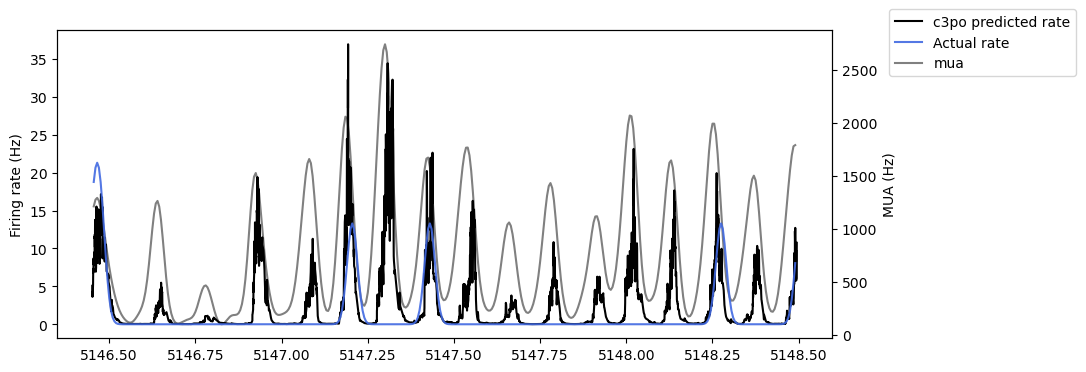

In [16]:
i =51
# i = 230

st = 301500
ind = slice(st, st + 6000)
st = 302500 +3*200
ind = slice(st, st + 3000)

t_st = analysis.t[ind][0]
t_end = analysis.t[ind][-1]

ind_rate = np.where(np.logical_and(t_spikes>t_st, t_spikes<t_end))[0]

fig, ax = plt.subplots(figsize=(10, 4))


ax2 = ax.twinx()
ax.set_zorder(2)
ax.patch.set_visible(False)
ax2.plot(t_spikes[ind_rate], mua[ind_rate,], label=f"mua", color="grey",zorder=-1)
# ax2.plot(analysis.t[ind], 1/delta_t[ind], label=f"1/delta_t", color="red",zorder=-1)

ax.plot(analysis.t[ind], np.exp(log_lam[ind,i]), label="c3po predicted rate", color="black")
ax.plot(t_spikes[ind_rate], rates[ind_rate, i], label=f"Actual rate", color="royalblue", alpha=.9,lw=1.5)

fig.legend(bbox_to_anchor=(.95, 0.95), loc="upper left", )
ax.set_ylabel("Firing rate (Hz)")
ax2.set_ylabel("MUA (Hz)")

# evalute the fit

array([  2,   4,   7,   9,  10,  11,  13,  14,  19,  20,  21,  22,  23,
        25,  26,  27,  28,  31,  32,  33,  34,  35,  36,  37,  38,  40,
        43,  44,  45,  47,  48,  51,  54,  56,  57,  58,  60,  62,  63,
        66,  67,  68,  69,  70,  72,  79,  80,  82,  83,  85,  86,  88,
        89,  90,  91,  93,  94,  95,  96,  97,  99, 100, 101, 102, 103,
       104, 106, 107, 109, 111, 112, 115, 118, 122, 123, 125, 126, 133,
       135, 138, 147, 150, 153, 154, 158, 160, 161, 170, 172, 175, 177,
       179, 181, 182, 187, 190, 192, 196, 198, 201, 202, 205, 206, 208,
       214, 216, 221, 222, 226, 227, 229, 230, 231, 236, 242, 244, 250,
       252, 254, 256, 257, 258, 259, 260, 262, 263, 266, 267, 268, 270,
       273, 280, 290, 294, 297, 300, 304, 307, 308, 312, 313, 314, 315,
       316, 317, 318, 321, 325, 327, 328, 331, 333, 334, 335, 336, 338,
       339, 340, 341, 344, 346, 347, 348, 351, 353, 354, 355, 356, 357,
       362, 364, 366, 367, 368, 369, 371, 374, 375, 376, 383, 38

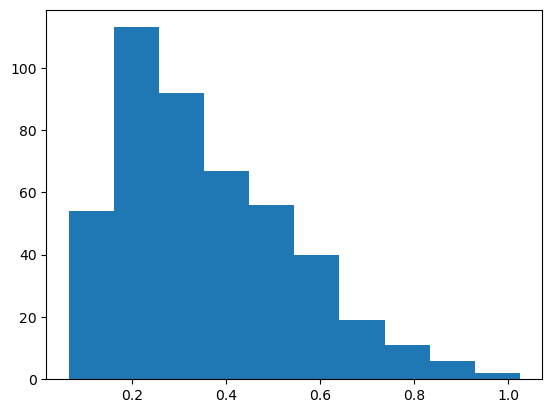

In [199]:
plt.hist(zz)
np.where(zz<.3)[0]

In [54]:
ind = np.where(gamma>.006)[0]
print(ind.size)
ind

6


array([ 60, 122, 205, 262, 338, 358])

(array([ 81., 135., 129.,  65.,  29.,  11.,   5.,   2.,   1.,   2.]),
 array([0.04749217, 0.50665618, 0.96582019, 1.4249842 , 1.88414821,
        2.34331222, 2.80247623, 3.26164024, 3.72080425, 4.17996826,
        4.63913227]),
 <BarContainer object of 10 artists>)

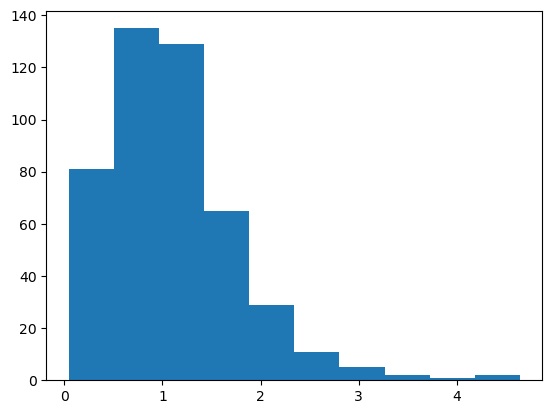

In [174]:
plt.hist(np.mean(rates,axis=0))